# 05particles: real particle tracks for the page

PF9, step 6. Releases particles all over the sea and moves them with the HYCOM currents of one month, to replace the made-up test flow on the underwater page.

How it works:
- The currents change every 2 days (one snapshot each); in between they are blended linearly, so the flow changes smoothly through the month (eddies, slowdowns and reversals included).
- Each particle keeps its depth as a **fraction of the local water depth** (for example 30% of the way down). The model gives no vertical currents, so particles do not rise or sink; the page will say so.
- Particles start at random times through the month and live a few days each, so the animation always has fresh particles everywhere.
- Half start anywhere in the window, half near the strait, so the squeeze through the gap is well covered.
- A particle stops if it reaches the coast or leaves the window.

Outputs in `docs/data/`: `tracks_YYYYMM.bin` (compact numbers) and `tracks_YYYYMM.json` (how to read them), plus a quick-look picture in `figures/`.

## Section 0. Settings

Lines marked `# <-` can be changed. `VISUAL:` settings only change what the page shows, not the physics.

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
HYCOM_DIR = PROJECT_DIR / "data" / "raw" / "hycom"
WEB_DIR = PROJECT_DIR / "docs" / "data"
FIG_DIR = PROJECT_DIR / "figures"

YEAR = 2019  # <- year of the month to track
MONTHS = [2, 5, 8, 11]  # <- months to make tracks for (each needs its snapshots in data/raw/hycom)

N_PARTICLES = 8000  # <- VISUAL: particles per month
NEAR_STRAIT_SHARE = 0.5  # <- share of particles released near the strait
NEAR_STRAIT_KM = 220  # <- "near the strait" radius in km
STRAIT_LAT = 65.75  # <- strait centre (between the Diomedes)
STRAIT_LON = 191.0  # <- degrees east
LIFE_MIN_DAYS = 3  # <- shortest particle life
LIFE_MAX_DAYS = 8  # <- longest particle life
FRAC_MIN = 0.05  # <- shallowest release, as a fraction of the water depth (0 = surface)
FRAC_MAX = 0.95  # <- deepest release (1 = seabed)
STEP_HOURS = 1.0  # <- time step of the particle movement
RECORD_HOURS = 3.0  # <- keep a position every RECORD_HOURS
SEED = 9  # <- random seed, so the same tracks come out every run

## Section 1. Libraries, page settings and helpers

In [2]:
import re
import json
import numpy as np
import pandas as pd
import xarray as xr
from PIL import Image
from pyproj import Transformer
import matplotlib.pyplot as plt

WEB_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
EARTH_R = 6371000.0

meta = json.loads((WEB_DIR / "bering_meta.json").read_text(encoding="utf-8"))
EXAG = meta["seabed_exaggeration"]
L, B, R, T = meta["local_bounds_m"]
to_local = Transformer.from_crs("EPSG:4326", meta["local_crs"], always_xy=True)

hp = np.asarray(Image.open(WEB_DIR / meta["height_png"]).convert("RGB")).astype(np.int64)
baked = (hp[..., 0] * 65536 + hp[..., 1] * 256 + hp[..., 2]) * 0.1 - 100000
seabed_depth = np.where(baked < 0, -baked / EXAG, 0.0)
H_ROWS, H_COLS = seabed_depth.shape
print("Page seabed grid:", H_COLS, "x", H_ROWS, "; seabed exaggeration", EXAG)


def page_seabed_depth(x, y):
    col = np.clip(((x - L) / (R - L) * (H_COLS - 1)).round().astype(int), 0, H_COLS - 1)
    row = np.clip(((T - y) / (T - B) * (H_ROWS - 1)).round().astype(int), 0, H_ROWS - 1)
    return seabed_depth[row, col]


def lonlat_to_local(lon, lat):
    lon180 = ((lon + 180) % 360) - 180
    return to_local.transform(lon180, lat)

Page seabed grid: 1454 x 964 ; seabed exaggeration 40


## Section 2. Particle tracking for one month

`track_month` loads the month's snapshots, then moves all particles together, one hour at a time, with a two-stage (midpoint) step for accuracy.

In [3]:
def load_month(year, month):
    files = sorted(HYCOM_DIR.glob(f"hycom_{year}{month:02d}*.nc"))
    assert files, f"No snapshots for {year}-{month:02d}"
    dates = [pd.Timestamp(re.search(r"(\d{8})", f.name).group(1)) for f in files]
    stack = []
    for f in files:
        ds = xr.open_dataset(f, engine="h5netcdf")
        if "time" in ds.dims:
            ds = ds.isel(time=0)
        stack.append(ds[["water_u", "water_v", "water_temp"]].load())
    hours = np.array([(d - dates[0]).total_seconds() / 3600 for d in dates])
    return stack, hours, dates


def prepare(stack):
    lat = stack[0]["lat"].values
    lon = stack[0]["lon"].values
    dep = stack[0]["depth"].values
    U = np.stack([s["water_u"].values for s in stack])
    V = np.stack([s["water_v"].values for s in stack])
    TT = np.stack([s["water_temp"].values for s in stack])
    valid = ~np.isnan(U[0])
    wet = valid.any(axis=0)
    last = valid.shape[0] - 1 - np.argmax(valid[::-1], axis=0)
    model_depth = np.where(wet, dep[last], 0.0)
    return lat, lon, dep, np.nan_to_num(U), np.nan_to_num(V), np.nan_to_num(TT), wet, model_depth


def sampler(lat, lon, dep, hours):
    lat0, dlat = lat[0], lat[1] - lat[0]
    lon0, dlon = lon[0], lon[1] - lon[0]
    ny, nx = len(lat), len(lon)

    def sample(F, t, py, px, pd_):
        ft = np.interp(t, hours, np.arange(len(hours)))
        i0 = np.clip(np.floor(ft).astype(int), 0, len(hours) - 2)
        wt = np.clip(ft - i0, 0, 1)
        fy = (py - lat0) / dlat
        fx = (px - lon0) / dlon
        iy = np.clip(np.floor(fy).astype(int), 0, ny - 2)
        ix = np.clip(np.floor(fx).astype(int), 0, nx - 2)
        wy = np.clip(fy - iy, 0, 1)
        wx = np.clip(fx - ix, 0, 1)
        k = np.clip(np.searchsorted(dep, pd_) - 1, 0, len(dep) - 2)
        wk = np.clip((pd_ - dep[k]) / (dep[k + 1] - dep[k]), 0, 1)
        out = 0.0
        for a, wa in ((i0, 1 - wt), (i0 + 1, wt)):
            for b, wb in ((k, 1 - wk), (k + 1, wk)):
                for c, wc in ((iy, 1 - wy), (iy + 1, wy)):
                    for e, we in ((ix, 1 - wx), (ix + 1, wx)):
                        out = out + F[a, b, c, e] * (wa * wb * wc * we)
        return out

    def cell(py, px):
        iy = np.clip(np.round((py - lat0) / dlat).astype(int), 0, ny - 1)
        ix = np.clip(np.round((px - lon0) / dlon).astype(int), 0, nx - 1)
        inside = (py >= lat[0]) & (py <= lat[-1]) & (px >= lon[0]) & (px <= lon[-1])
        return iy, ix, inside

    return sample, cell

In [4]:
def seed(n, rng, lat, lon, wet, month_hours):
    pts_lat = []
    pts_lon = []
    n_near = int(n * NEAR_STRAIT_SHARE)
    while len(pts_lat) < n:
        m = 20000
        if len(pts_lat) < n_near:
            r = NEAR_STRAIT_KM * 1000 * np.sqrt(rng.random(m))
            a = rng.random(m) * 2 * np.pi
            cand_lat = STRAIT_LAT + np.degrees(r * np.sin(a) / EARTH_R)
            cand_lon = STRAIT_LON + np.degrees(r * np.cos(a) / (EARTH_R * np.cos(np.radians(STRAIT_LAT))))
        else:
            cand_lat = rng.uniform(lat[0], lat[-1], m)
            cand_lon = rng.uniform(lon[0], lon[-1], m)
        iy = np.clip(np.round((cand_lat - lat[0]) / (lat[1] - lat[0])).astype(int), 0, len(lat) - 1)
        ix = np.clip(np.round((cand_lon - lon[0]) / (lon[1] - lon[0])).astype(int), 0, len(lon) - 1)
        x, y = lonlat_to_local(cand_lon, cand_lat)
        ok = wet[iy, ix] & (x > L) & (x < R) & (y > B) & (y < T) & (page_seabed_depth(np.asarray(x), np.asarray(y)) > 1)
        keep = n_near - len(pts_lat) if len(pts_lat) < n_near else n - len(pts_lat)
        pts_lat.extend(cand_lat[ok][:keep])
        pts_lon.extend(cand_lon[ok][:keep])
    life = rng.uniform(LIFE_MIN_DAYS, LIFE_MAX_DAYS, n) * 24
    start = rng.uniform(0, max(1.0, month_hours - LIFE_MIN_DAYS * 24), n)
    end = np.minimum(start + life, month_hours)
    frac = rng.uniform(FRAC_MIN, FRAC_MAX, n)
    return np.array(pts_lat), np.array(pts_lon), start, end, frac


def track_month(year, month):
    rng = np.random.default_rng(SEED + month)
    stack, hours, dates = load_month(year, month)
    lat, lon, dep, U, V, TT, wet, model_depth = prepare(stack)
    month_hours = hours[-1] + 48
    sample, cell = sampler(lat, lon, dep, hours)
    plat, plon, start, end, frac = seed(N_PARTICLES, rng, lat, lon, wet, month_hours)
    n = len(plat)
    alive = np.ones(n, bool)
    rec_every = int(round(RECORD_HOURS / STEP_HOURS))
    n_steps = int(np.ceil(month_hours / STEP_HOURS))
    rec_lat = np.full((n_steps // rec_every + 1, n), np.nan, np.float32)
    rec_lon = np.full_like(rec_lat, np.nan)
    temp0 = np.full(n, np.nan)
    dt = STEP_HOURS * 3600

    def velocity(t, py, px, fr):
        iy, ix, inside = cell(py, px)
        depth = fr * model_depth[iy, ix]
        u = sample(U, t, py, px, depth)
        v = sample(V, t, py, px, depth)
        return u, v, inside & wet[iy, ix]

    for s in range(n_steps + 1):
        t = s * STEP_HOURS
        active = alive & (t >= start) & (t <= end)
        if s % rec_every == 0:
            r = s // rec_every
            rec_lat[r, active] = plat[active]
            rec_lon[r, active] = plon[active]
        newly = active & np.isnan(temp0)
        if newly.any():
            iy, ix, _ = cell(plat[newly], plon[newly])
            temp0[newly] = sample(TT, t, plat[newly], plon[newly], frac[newly] * model_depth[iy, ix])
        if not active.any():
            continue
        a = np.where(active)[0]
        u1, v1, ok1 = velocity(t, plat[a], plon[a], frac[a])
        mid_lat = plat[a] + np.degrees(v1 * dt / 2 / EARTH_R)
        mid_lon = plon[a] + np.degrees(u1 * dt / 2 / (EARTH_R * np.cos(np.radians(plat[a]))))
        u2, v2, ok2 = velocity(t + STEP_HOURS / 2, mid_lat, mid_lon, frac[a])
        new_lat = plat[a] + np.degrees(v2 * dt / EARTH_R)
        new_lon = plon[a] + np.degrees(u2 * dt / (EARTH_R * np.cos(np.radians(plat[a]))))
        _, _, ok3 = velocity(t + STEP_HOURS, new_lat, new_lon, frac[a])
        good = ok1 & ok2 & ok3
        plat[a[good]] = new_lat[good]
        plon[a[good]] = new_lon[good]
        alive[a[~good]] = False
    return {"rec_lat": rec_lat, "rec_lon": rec_lon, "frac": frac, "temp0": temp0, "dates": dates, "month_hours": month_hours, "n_snapshots": len(hours)}

## Section 3. Convert to page coordinates and save

Positions become local metres on the page's map (stored in 100 m units), and depth becomes the page's baked height: `-fraction x seabed depth on the page x exaggeration`, so every particle sits inside the drawn water column.

File layout (`tracks_YYYYMM.bin`, little-endian): `start` uint16 (first record index) x n, `count` uint16 x n, `temp` int16 (°C x 100) x n, `frac` uint16 (x 1000) x n, then `xyz` int16 for all points (x and y in 100 m units from the map centre, z in baked metres).

In [5]:
def save_tracks(res, year, month):
    rec_lat = res["rec_lat"]
    rec_lon = res["rec_lon"]
    n = rec_lat.shape[1]
    starts = np.zeros(n, np.uint16)
    counts = np.zeros(n, np.uint16)
    xyz = []
    for i in range(n):
        ok = ~np.isnan(rec_lat[:, i])
        idx = np.where(ok)[0]
        if len(idx) < 2:
            continue
        x, y = lonlat_to_local(rec_lon[idx, i].astype(float), rec_lat[idx, i].astype(float))
        x = np.asarray(x)
        y = np.asarray(y)
        z = -res["frac"][i] * np.maximum(page_seabed_depth(x, y), 2.0) * EXAG
        starts[i] = idx[0]
        counts[i] = len(idx)
        xyz.append(np.stack([np.round(x / 100), np.round(y / 100), np.round(z)], axis=1).astype(np.int16))
    keep = counts >= 2
    temps = np.round(np.nan_to_num(res["temp0"], nan=0) * 100).astype(np.int16)
    fracs = np.round(res["frac"] * 1000).astype(np.uint16)
    body = np.concatenate(xyz).ravel()
    out_bin = WEB_DIR / f"tracks_{year}{month:02d}.bin"
    with open(out_bin, "wb") as f:
        f.write(starts[keep].tobytes())
        f.write(counts[keep].tobytes())
        f.write(temps[keep].tobytes())
        f.write(fracs[keep].tobytes())
        f.write(body.astype("<i2").tobytes())
    info = {}
    info["year"] = year
    info["month"] = month
    info["n"] = int(keep.sum())
    info["total_points"] = int(counts[keep].sum())
    info["record_hours"] = RECORD_HOURS
    info["month_hours"] = float(res["month_hours"])
    info["xy_unit_m"] = 100
    info["z_unit"] = "baked metres (seabed exaggeration included)"
    info["seabed_exaggeration"] = EXAG
    info["snapshots"] = res["n_snapshots"]
    info["first_snapshot"] = str(res["dates"][0].date())
    info["last_snapshot"] = str(res["dates"][-1].date())
    info["source"] = ("HYCOM GOFS 3.1 reanalysis GLBv0.08 expt_53.X" if year <= 2015 else "HYCOM GOFS 3.1 analysis GLBy0.08 expt_93.0") + "; particles keep their fraction of the local water depth (no vertical motion)"
    (WEB_DIR / f"tracks_{year}{month:02d}.json").write_text(json.dumps(info, indent=1), encoding="utf-8")
    return out_bin, info

In [6]:
results = {}
for m in MONTHS:
    res = track_month(YEAR, m)
    out_bin, info = save_tracks(res, YEAR, m)
    results[m] = res
    lens = np.isfinite(res["rec_lat"]).sum(axis=0) * RECORD_HOURS / 24
    print(f"{YEAR}-{m:02d}: {info['n']} particles, {info['total_points']} points, {round(out_bin.stat().st_size / 1e6, 2)} MB; median track {np.median(lens):.1f} days; snapshots {info['first_snapshot']} to {info['last_snapshot']}")

2019-02: 7995 particles, 336385 points, 2.08 MB; median track 5.2 days; snapshots 2019-02-01 to 2019-02-27
2019-05: 7992 particles, 338894 points, 2.1 MB; median track 5.2 days; snapshots 2019-05-01 to 2019-05-31
2019-08: 7987 particles, 335804 points, 2.08 MB; median track 5.2 days; snapshots 2019-08-01 to 2019-08-31
2019-11: 7992 particles, 334860 points, 2.07 MB; median track 5.2 days; snapshots 2019-11-01 to 2019-11-29


## Section 4. Quick look

All tracks of each month on the page's map (km from the map centre), coloured by depth fraction: light near the surface, dark near the seabed. Grey line = coast.

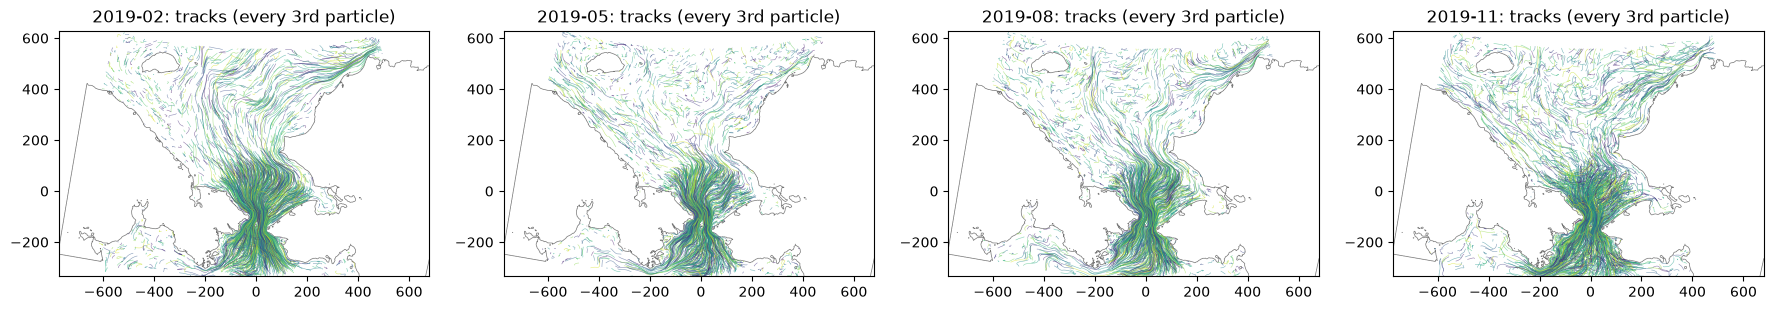

In [7]:
coast_x = np.linspace(L, R, H_COLS) / 1000
coast_y = np.linspace(T, B, H_ROWS) / 1000
fig, axes = plt.subplots(1, len(MONTHS), figsize=(5.5 * len(MONTHS), 4.4), squeeze=False)
for ax, m in zip(axes[0], MONTHS):
    res = results[m]
    ax.contour(coast_x, coast_y, baked, levels=[0], colors="#777777", linewidths=0.5)
    cmap = plt.get_cmap("viridis_r")
    for i in range(0, res["rec_lat"].shape[1], 3):
        ok = ~np.isnan(res["rec_lat"][:, i])
        if ok.sum() < 2:
            continue
        x, y = lonlat_to_local(res["rec_lon"][ok, i].astype(float), res["rec_lat"][ok, i].astype(float))
        ax.plot(np.asarray(x) / 1000, np.asarray(y) / 1000, color=cmap(res["frac"][i]), linewidth=0.4, alpha=0.6)
    ax.set_aspect("equal")
    ax.set_title(f"{YEAR}-{m:02d}: tracks (every 3rd particle)")
    ax.set_xlim(L / 1000, R / 1000)
    ax.set_ylim(B / 1000, T / 1000)
fig.savefig(FIG_DIR / f"05_tracks_{YEAR}.png", dpi=140, bbox_inches="tight")
plt.show()

___
**END**